# Figure3 Co2 Attribution

Reproduces panels used in the main manuscript. Generated files are written to `logs/scripts/figure3_co2_attribution/`.


In [1]:
import os, sys
from pathlib import Path

if Path(os.getcwd()).stem == 'scripts':
    ROOT = Path(os.getcwd()).parent
else:
    ROOT = Path(os.getcwd())

sys.path.append(str(ROOT))
os.chdir(ROOT)

In [2]:
import re
import sys
import json
import yaml
import shlex
import random
import dotenv
import signal
import logging
import datetime
import nd2py as nd
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from socket import gethostname
from argparse import Namespace
from argparse import ArgumentParser
from nd2py.utils import init_logger
from setproctitle import setproctitle
from src.utils import add_negation_flags, tag2ansi, log_exception
from src.core import Triplet, Individual
from src.assistant import Assistant
from src.ai_scientist import AIScientist
from src.ai_scientist_parallel import AIScientistParallel
from src.utils import wrap_ansi

import warnings
# warnings.simplefilter('error', RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="nd2py")

dotenv.load_dotenv()
_logger = logging.getLogger('src')

args = Namespace(**json.load(open('data/cache/default_args.json', 'r')))
args.save_dir = './logs/scripts'
args.exp_name = 'figure3_co2_attribution'
args.train_period = ['all', 'all']
args.test_period = ['all', 'all']
args.a_skill_after_2004 = 0.0

## Build Save Path
if args.exp_name is None:
    now = datetime.now()
    date = now.strftime("%Y%m%d")
    curr = now.strftime("%H%M%S")
    host = gethostname()
    exp_name = f'{date}_{args.name}_{curr}_{host}'
    exp_name = re.compile(r'[ <>:"/\\|?*\x00-\x1f]').sub('_', exp_name.strip())
    exp_name = exp_name or 'unnamed'
    exp_name = exp_name[:255] # Max filename length on most filesystems
    args.exp_name = exp_name
save_path = Path(args.save_dir) / args.exp_name
if not save_path.exists():
    save_path.mkdir(parents=True, exist_ok=True)
else:
    _logger.warning(f"Save path {save_path} already exists.")
args.save_path = str(save_path)

## Set Random State
if args.random_state is None:
    args.random_state = random.randint(0, 2**31 - 1)
## Set Command
args.command = ' '.join(map(shlex.quote, [sys.executable, *sys.argv]))

args.debug = True

## Init Logger
init_logger(
    "src", 
    exp_name=args.exp_name, 
    log_file=save_path / "info.log", 
    info_level='debug' if args.debug else 'info',
    show_lineno_for_all_levels=args.debug,
)
nd2py_logger = logging.getLogger("nd2py")
nd2py_logger.setLevel(_logger.level)
nd2py_logger.handlers = _logger.handlers.copy()

## Save Args
args_path = save_path / "args.json"
if args_path.exists():
    i = 1
    while args_path.with_suffix(f".json.{i}").exists(): i += 1
    args_path.rename(args_path.with_suffix(f".json.{i}"))
    _logger.warning(f"args.json already exists, backup to args.json.{i}")
_logger.note(f"Args: {args}")
with open(args_path, "w") as f:
    json.dump(vars(args), f, indent=4, ensure_ascii=False)

# Start the main process
setproctitle(f"{args.exp_name}@ZihanYu")

## Load Assistant
assistant = Assistant(args)
## Load Data
# 加载变量
variables = assistant.load_variables()
# 加载数据
df_all = assistant.load_data(normalize_co2=False)
# 划分数据
if True:
    train_start, train_end = args.train_period
    test_start, test_end = args.test_period
    train_start = pd.Period(train_start, freq='M') if train_start != 'all' else df_all.index[0]
    train_end = pd.Period(train_end, freq='M') if train_end != 'all' else df_all.index[-1]
    test_start = pd.Period(test_start, freq='M') if test_start != 'all' else df_all.index[0]
    test_end = pd.Period(test_end, freq='M') if test_end != 'all' else df_all.index[-1]
    df_train = df_all.loc[train_start:train_end]
    df_test = df_all.loc[test_start:test_end]
elif False:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
else:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=1999, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=2000, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
# 准备拓扑
edge_list, num_nodes = assistant.load_topology()
# 打印日志
_logger.info(
    f"Data loaded: {len(df_all)} samples, "
    f"where {len(df_train)}({len(df_train)/len(df_all):.2%}) "
    f"from {df_train.index[0]} to {df_train.index[-1]} for training, "
    f"and {len(df_test)}({len(df_test)/len(df_all):.2%}) "
    f"from {df_test.index[0]} to {df_test.index[-1]} for testing."
)
_logger.info(
    f"Variables: " + ", ".join(f'{var_name}({len(sub_df)})' for var_name, sub_df in df_all.T.groupby(level=0)) + "."
)
## Load Seed Individuals
seed_individuals = assistant.load_seed_individuals()

## Initialize Runner
Runner = AIScientistParallel if args.parallel else AIScientist
kwargs = dict(
    args=args,
    assistant=assistant,
    variables=variables,
    binary=[
        getattr(nd, name) for name in args.binary
        # nd.Add, nd.Sub, nd.Mul, nd.Div
    ],
    unary=[
        getattr(nd, name) for name in args.unary
        # nd.Sin, nd.Cos,
        # nd.Exp, nd.LogAbs,
        # nd.Sigmoid, nd.Tanh,
        # nd.Pow2, nd.Pow3, nd.SqrtAbs,
        # nd.Aggr, nd.Readout, nd.Sour, nd.Targ,
    ],
    edge_list=edge_list,
    num_nodes=num_nodes,
    seed_individuals=seed_individuals,
)
_logger.note(f"Initializing Runner with args: {kwargs}")
est = Runner(**kwargs)
# Set Clip Bounds
est.evaluator.simulator.set_clip_bounds(df_all, clip_factor=args.clip_factor)

Save path logs/scripts/figure3_co2_attribution already exists.
[figure3_co2_attribution|src|W|Oct15 11:24:35|0:00:00.001970] (../../../../../../tmp/ipykernel_2933728/796366415.py:86) args.json already exists, backup to args.json.8
[figure3_co2_attribution|src|N|Oct15 11:24:35|0:00:00.003433] (venv/lib/python3.12/site-packages/nd2py/utils/logger.py:62) Args: Namespace(name='Reduce_320_230_368', setting='only_co2', exp_name='figure3_co2_attribution', llm_model=None, llm_provider=None, seed_individuals=['co2_320_230_368'], load_seed_individuals=[], use_seed_individuals_only=True, num_workers=24, parallel=True, timeout=240, population_size=200, n_iter=300, programs_per_prompt=2, generate_per_prompt=8, expire_iter=1, keep_best=False, random_state=1581316702, score_func='tanh', a_rmse=0.0, a_trajrmse=0.0, a_skill_cv_sum=0.0, a_skill_cv_sum_inner=0.0, a_skill_cv_mean=0.0, a_ENSO_skill_cv=1.0, a_Total_skill_cv=10.0, a_skill_sum_inner=0.0, a_skill_sum=0.0, a_skill_mean=0.0, a_ENSO_skill=0.0, a_

In [3]:
args.a_rmse = 0.0
args.a_trajrmse = 0.0
args.a_skill_cv_sum = 0.0
args.a_skill_cv_sum_inner = 0.0
args.a_skill_cv_mean = 0.0
args.a_ENSO_skill_cv = 1.0
args.a_ATL3_skill_cv = 1.0
args.a_SASD_skill_cv = 1.0
args.a_Total_skill_cv = 10.0
args.a_skill_sum_inner = 0.0
args.a_skill_sum = 0.0
args.a_skill_mean = 0.0
args.a_ENSO_skill = 0.0
args.a_IOB_skill = 0.0
args.a_SASD_skill = 0.0
args.a_Total_skill = 0.0
args.a_skill_after_2004 = 1.0
args.a_length = 1.0
args.a_params = 0.0
args.a_std = 0.25
args.a_skewness = 0.25
args.a_spectrum = 0.25
args.a_leadlag = 0.25
args.a_forecast = 0.0
args.a_contain_co2 = 0.0
args.max_month = 40
args.a_correlation_auc_sum = 0.0
args.a_correlation_auc_cv_sum = 0.0

args.damp = 1e-1
args.atol = 1e-6
args.btol = 1e-6
args.iter_lim = None

In [4]:
baseline_indiv = assistant.load_baseline_indiv()

def evaluate6(indiv, df_test, df_train=None):

    if df_train is not None:
        if indiv.fitness is not None:
            _logger.warning("Refitting dynamics for individual during set_fitness.")
        dynamics = est.evaluator.assistant.triplet_to_dynamics(indiv.triplet)
        dynamics, mse = est.evaluator.fitter.fit_parameters(dynamics, df_train)
        indiv.dynamics = dynamics
        if not np.isfinite(mse):
            indiv.fitness = -np.inf
            indiv.detail = {"error": f"Invalid MSE {mse}"}
            return

    dt = df_test['t'].values[1, 0] - df_test['t'].values[0, 0]
    ## 无噪声预测
    PREDICTION = est.evaluator.simulator.get_simulation_with_forcing(
        indiv.dynamics, df_test[['x', 'h', 't']], dt, df_test.drop(columns=['x', 'h', 't'], level=0),
        max_month=est.evaluator.args.max_month, tqdm_desc=None
    )
    return PREDICTION

In [5]:
import warnings

# 专门屏蔽 QuadContourSet 的光栅化警告
warnings.filterwarnings(
    "ignore", 
    message="Rasterization of '<matplotlib.contour.QuadContourSet", 
    category=UserWarning
)

# 移除所有模态的 CO2，看各个模态怎么变

In [6]:
# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = Variable('damping_flag') * x + \
            Variable('recharging_flag') * mode['ENSO'] * h + \
            Variable('co2_flag') * log(u_co2) + \
            aggr( 
                Variable('slow_flag') * sour(x) + \
                Variable('fast_flag') * tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x))
            )
    dh_dt = Variable('damping_flag') * h + \
            Variable('Tbar_flag') * readout(x) ** 2 + \
            aggr(
                Variable('slow_flag') * sour(x) + \
                Variable('fast_flag') * tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x))
            )
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)

if True:
    args.max_month = 36

    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 1
    df_all[('slow_flag', 'value')] = 1
    df_all[('fast_flag', 'value')] = 1
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])

    df_all[('damping_flag', 'value')] = 1
    df_all[('recharging_flag', 'value')] = 1
    df_all[('co2_flag', 'value')] = 0
    df_all[('slow_flag', 'value')] = 1
    df_all[('fast_flag', 'value')] = 1
    df_all[('Tbar_flag', 'value')] = 1

    PREDICTION_wo_co2 = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)

[figure3_co2_attribution|data_loader|D|Oct15 11:24:35|0:00:00.220762] (src/assistant/data_loader.py:55) Detrending ENSO SST with coefficients: [-7.14225957e-07  3.27857303e-04  8.16754329e-02]
[figure3_co2_attribution|data_loader|D|Oct15 11:24:35|0:00:00.222875] (src/assistant/data_loader.py:55) Detrending NPMM SST with coefficients: [ 5.23786876e-06 -5.07198219e-03  1.14418764e+00]
[figure3_co2_attribution|data_loader|D|Oct15 11:24:35|0:00:00.224557] (src/assistant/data_loader.py:55) Detrending SPMM SST with coefficients: [-6.20970905e-07 -3.72185672e-04  3.92080518e-01]
[figure3_co2_attribution|data_loader|D|Oct15 11:24:35|0:00:00.226176] (src/assistant/data_loader.py:55) Detrending IOB SST with coefficients: [ 1.84648014e-06 -1.01057274e-03  8.39776510e-02]
[figure3_co2_attribution|data_loader|D|Oct15 11:24:35|0:00:00.227735] (src/assistant/data_loader.py:55) Detrending IOD SST with coefficients: [-1.41512104e-06  1.72745765e-03 -5.17341840e-01]
[figure3_co2_attribution|data_loader|

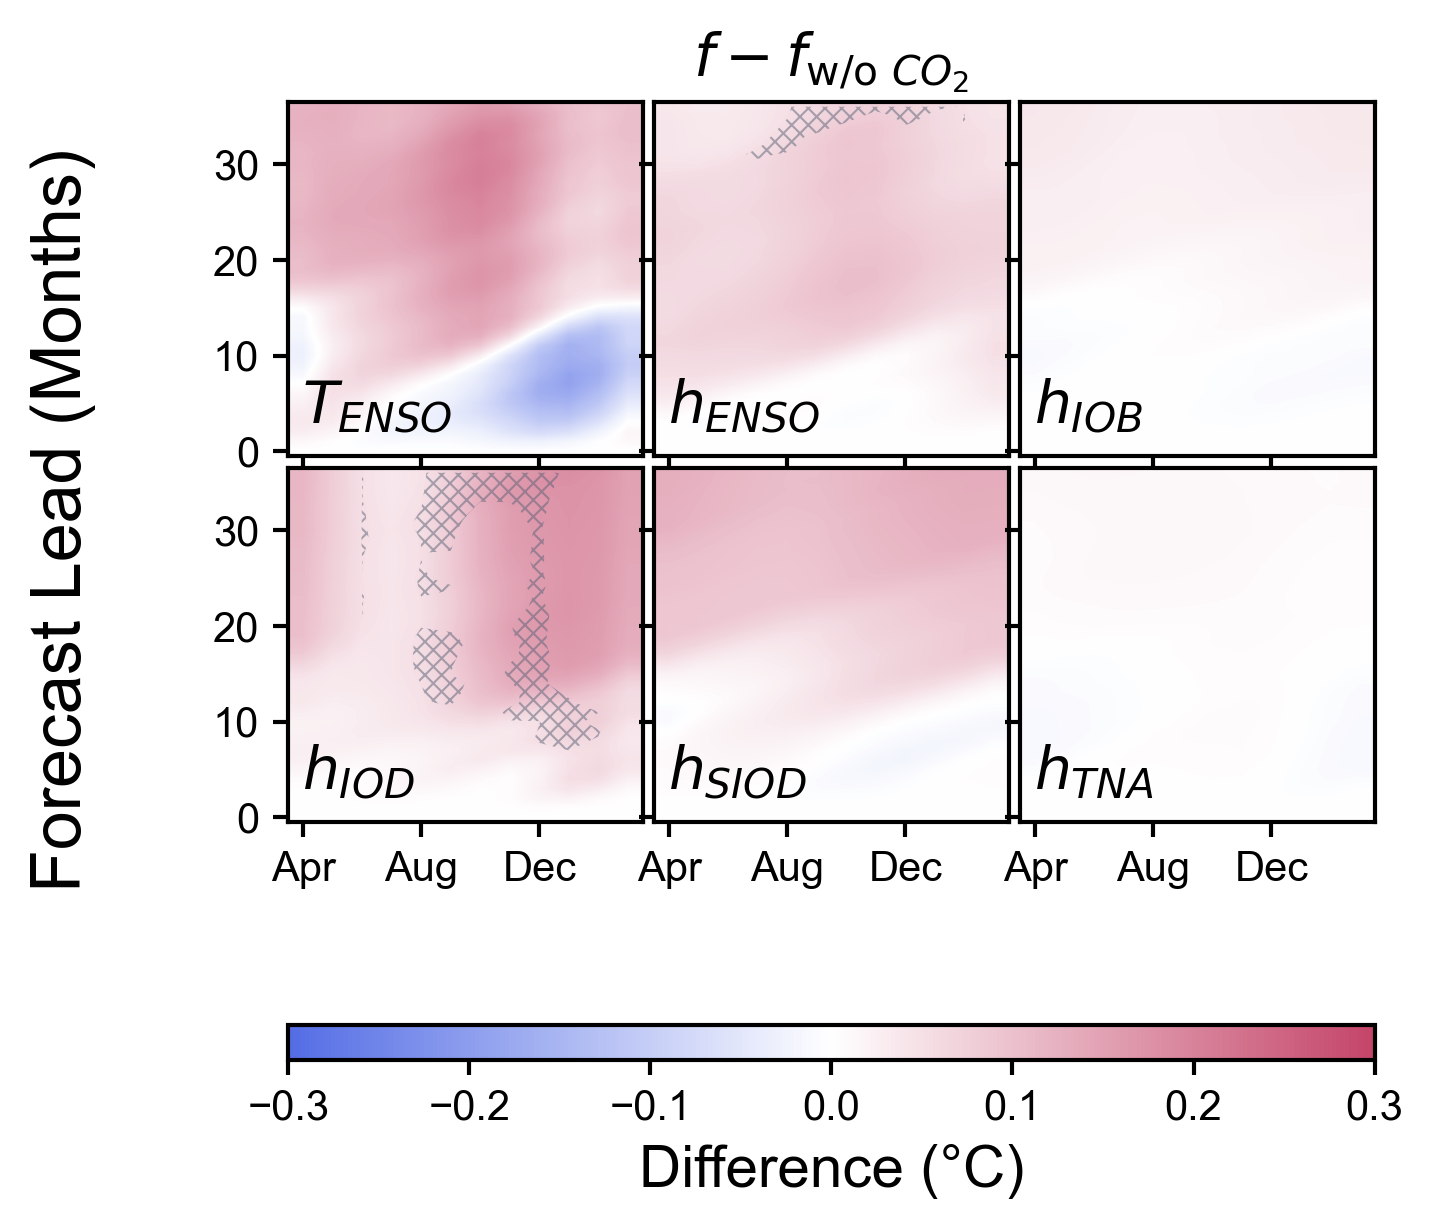

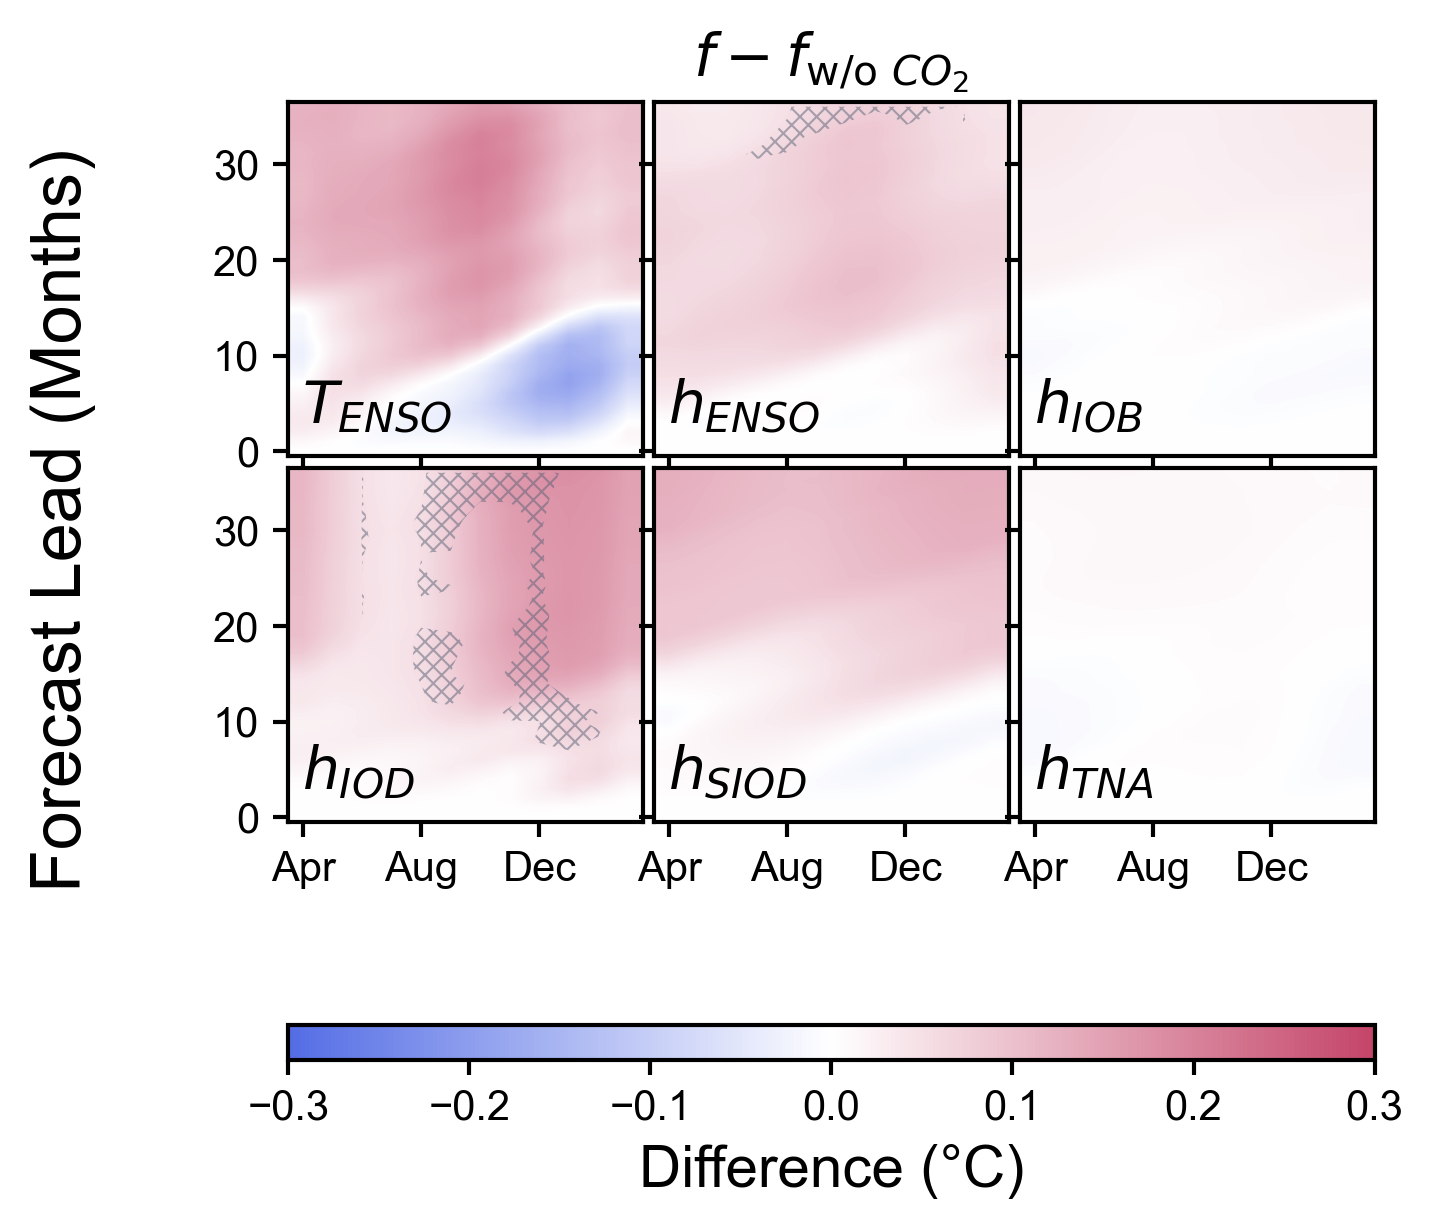

In [7]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from nd2py.utils.plot import get_fig

# The six subpanels retained in main-text Figure 3a.  This is the temperature
# difference used by the manuscript, not the difference between two MAEs.
panels = [('x', 'ENSO'), ('h', 'ENSO'), ('h', 'IOB'), ('h', 'IOD'), ('h', 'SIOD'), ('h', 'TNA')]
fi, fig, axes = get_fig(
    2, 3, AW=3, A_ratio=1, VS=0.2, HS=0.2, LM=5, RM=5, TM=5, BM=7, dpi=300, sharex=True, sharey=True, lw=1, fontsize=14
)
var_map = {'x': 'T', 'h': 'h'}
months = ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']
stop = PREDICTION.index.get_level_values('time') + PREDICTION.index.get_level_values('lead')
stop_month = stop.strftime('%b')
norm = plt.Normalize(vmin=-0.3, vmax=0.3)
cmap = mcolors.LinearSegmentedColormap.from_list('custom_rdbu', ['#546de5', '#ffffff', '#c44569'])

for k, ((var, mode), ax) in enumerate(zip(panels, axes)):
    full = PREDICTION[(var, mode)].to_frame('value').reset_index().assign(stop_month=stop_month).pivot_table(index='lead', columns='stop_month', values='value')[months]
    ablated = PREDICTION_wo_co2[(var, mode)].to_frame('value').reset_index().assign(stop_month=stop_month).pivot_table(index='lead', columns='stop_month', values='value')[months]
    difference = full - ablated
    im = ax.imshow(difference.values, interpolation='bilinear', aspect='auto', rasterized=True,
                   norm=norm, cmap=cmap, origin='lower')

    # Cross-hatching in the published panel marks points where ablation makes
    # the absolute forecast error worse by more than 0.05 degC.
    mae_difference = np.abs(full - full.loc[[0]].values) - np.abs(ablated - ablated.loc[[0]].values)
    xx, yy = np.meshgrid(np.arange(difference.shape[1]), np.arange(difference.shape[0]))
    with plt.rc_context({'hatch.color': '#59627580', 'hatch.linewidth': 0.5}):
        hatch = ax.contourf(xx, yy, mae_difference.values, levels=[0.05, np.inf],
                            hatches=['xxxxxx'], colors='none', zorder=10000)
    with plt.rc_context({'hatch.color': '#dfe6e9'}):
        invalid = ax.contourf(xx, yy, np.isnan(difference.values), levels=[0.5, 1.5],
                              hatches=['////'], colors='none', zorder=10001)

    ax.text(0.04, 0.06, rf'${var_map[var]}_{{{mode}}}$', ha='left', va='bottom', transform=ax.transAxes)
    ax.set_xticks(np.arange(0, 12, 4), [months[i] for i in range(0, 12, 4)])
    if k < 3:
        ax.tick_params(labelbottom=False)
    if k % 3:
        ax.tick_params(labelleft=False)

fig.supylabel('Forecast Lead (Months)', x=0.02)
axes[1].set_title(r'$f-f_{\mathrm{w/o}\ CO_2}$')
# Use a dedicated colorbar axis in the bottom margin.  Passing the panel axes
# to fig.colorbar would shrink their height and turn the square panels into
# rectangles.
cax = fig.add_axes([fi['r_LM'], 0.12, 1 - fi['r_LM'] - fi['r_RM'], 0.025])
fig.colorbar(im, cax=cax, orientation='horizontal', label='Difference (°C)')
fig.savefig(save_path / f'Fig3a.png', dpi=300, transparent=True)
fig.savefig(save_path / f'Fig3a.svg', dpi=300, transparent=True)
fig.savefig(save_path / f'Fig3a.pdf', dpi=300, transparent=True)
fig


# 移除各个模态的 CO2，看对应模态怎么变

In [8]:
from tqdm import tqdm

df_all[('damping_flag', 'value')] = 1
df_all[('recharging_flag', 'value')] = 1
# df_all[('co2_flag', 'value')] = 0
df_all = df_all.drop('co2_flag', axis=1, level=0)
df_all[('slow_flag', 'value')] = 1
df_all[('fast_flag', 'value')] = 1
df_all[('Tbar_flag', 'value')] = 1

PREDICTION_wo_co2_of_modes = {}
for mode in tqdm(assistant.modes, desc="co2_flag"):
    df_all[pd.MultiIndex.from_product([['co2_flag'], assistant.modes])] = 1 - df_all[mode][assistant.modes]
    PREDICTION_wo_co2_of_modes[mode] = evaluate6(indiv, df_all.loc['1979-01':'2024-12'], None)
df_all = df_all.drop('co2_flag', axis=1, level=0)


co2_flag:   0%|          | 0/9 [00:00<?, ?it/s]/tmp/ipykernel_2933728/44671517.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_all[pd.MultiIndex.from_product([['co2_flag'], assistant.modes])] = 1 - df_all[mode][assistant.modes]
co2_flag: 100%|██████████| 9/9 [00:26<00:00,  2.89s/it]


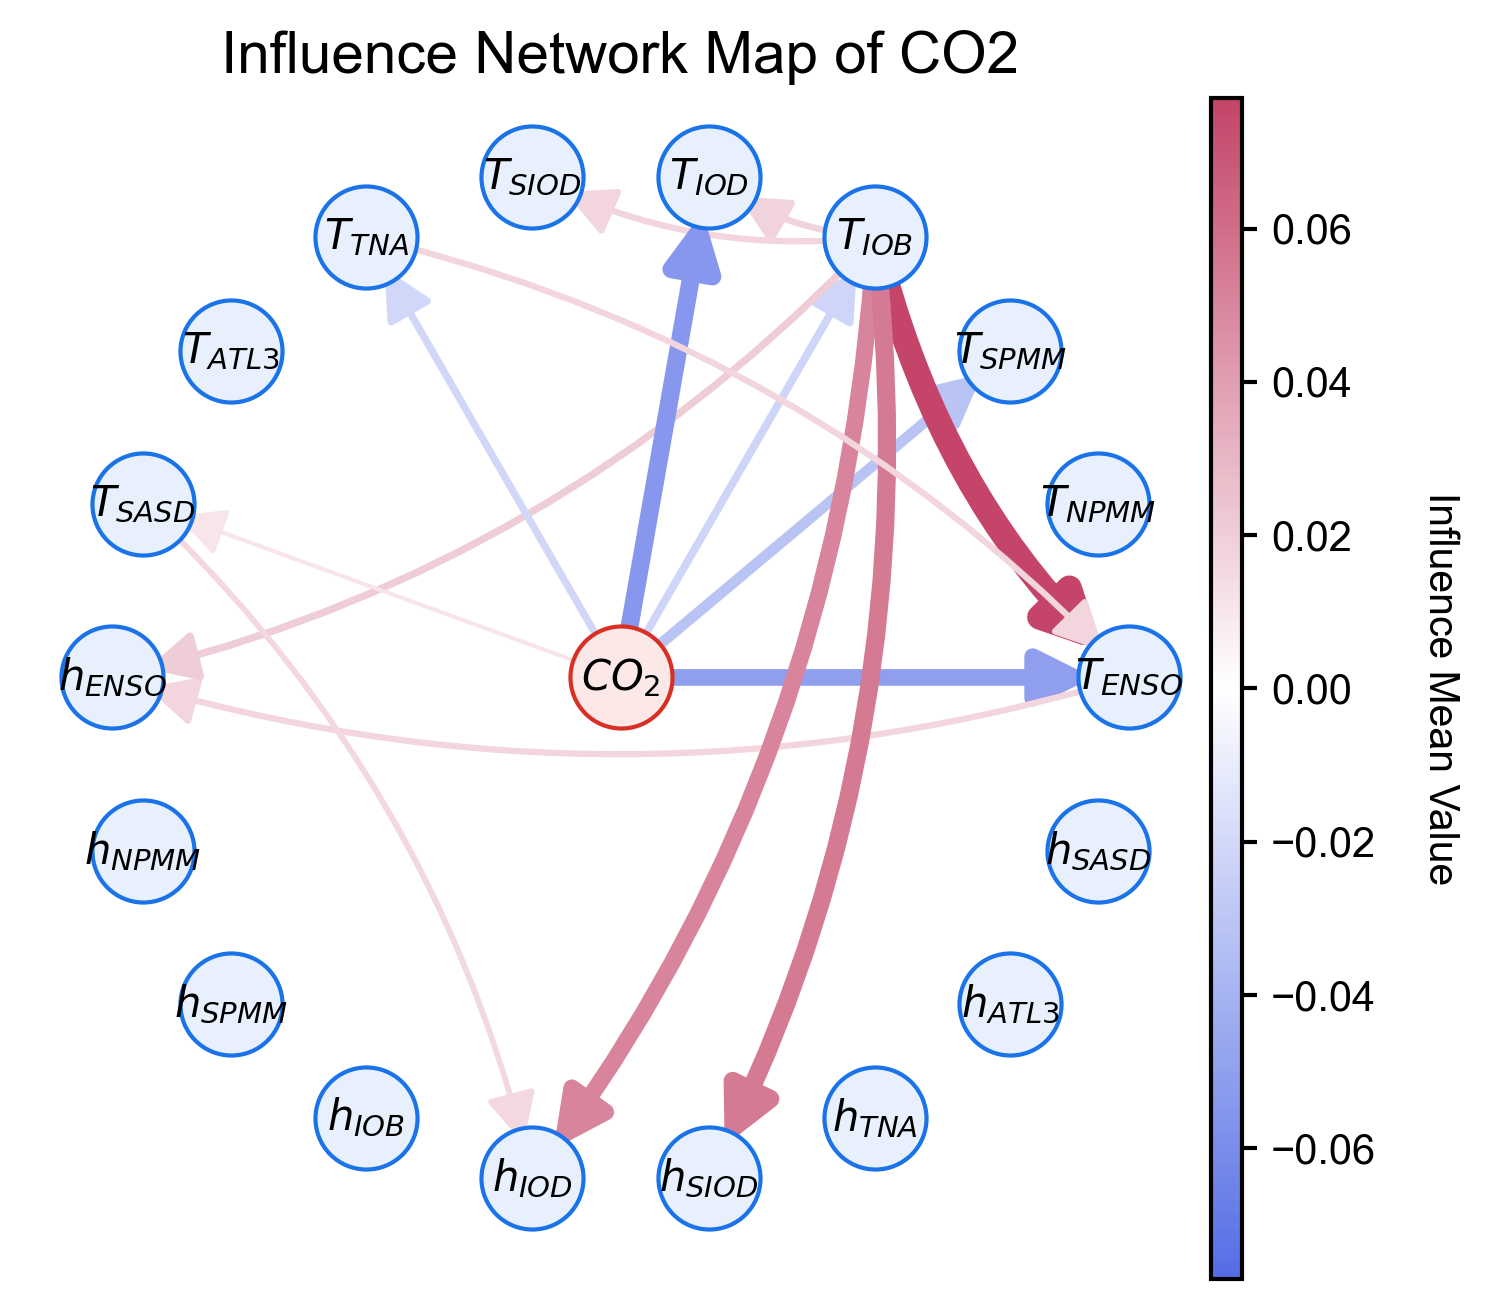

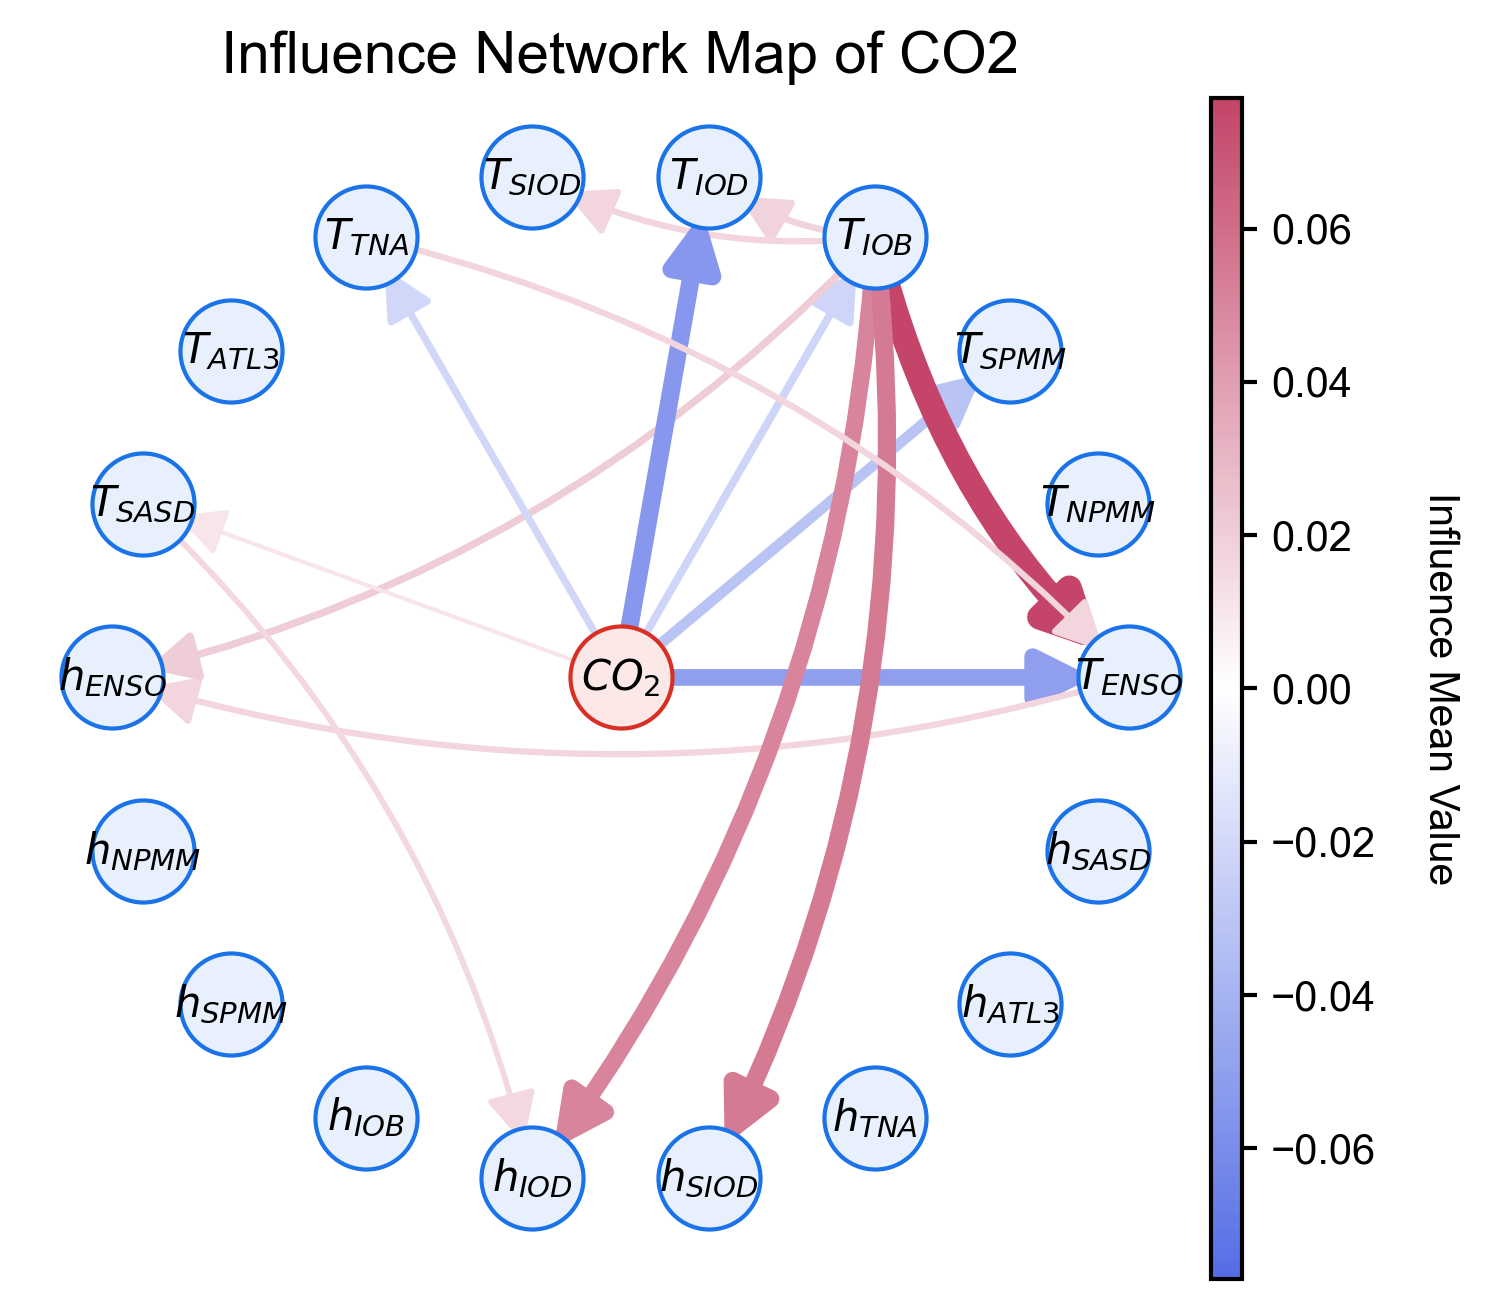

In [9]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy import stats
from nd2py.utils.plot import get_fig

var_map = {'x': 'T', 'h': 'h'}
influence = {}
for ablation_mode in assistant.modes:
    for var in ['x', 'h']:
        for mode in assistant.modes:
            if True: # CO2
                stop = PREDICTION.index.get_level_values('time') + PREDICTION.index.get_level_values('lead')
                stop_month = stop.strftime('%b')
                df_plot = (PREDICTION - PREDICTION_wo_co2_of_modes[ablation_mode])[(var, mode)].to_frame(f'{var}_{mode}').reset_index().assign(stop_month=stop_month).pivot_table(index='lead', columns='stop_month', values=f'{var}_{mode}')
                df_plot = df_plot[['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct' , 'Nov', 'Dec', 'Jan', 'Feb', 'Mar']]

                influence[(var_map['x'], ablation_mode, var_map[var], mode)] = df_plot.values

G = nx.DiGraph()
edge_features = {}

all_abs_means = [abs(np.nanmean(v)) for v in influence.values()]
threshold = np.max(all_abs_means) * 0.2


for key, values in influence.items():
    src_node = f"${key[0]}_{{{key[1]}}}$"
    tgt_node = f"${key[2]}_{{{key[3]}}}$"

    values = np.array(values)
    values = values[~np.isnan(values)] # 剔除空值
    mean_val = np.mean(values)
    if abs(mean_val) <= threshold:
        if not (src_node == tgt_node == '$T_{SASD}$'):
            continue

    # 核心：将自环重定向给 CO2
    if src_node == tgt_node:
        src_node = '$CO_2$'
        
    G.add_edge(src_node, tgt_node)
    edge_features[(src_node, tgt_node)] = {'mean': mean_val}

main_nodes = []
for var in ['T', 'h']:
    for mode in assistant.modes:
        main_nodes.append(f'${var}_{{{mode}}}$')
        G.add_node(f'${var}_{{{mode}}}$')
pos = nx.circular_layout(main_nodes)
pos['$CO_2$'] = np.array([0.0, 0.0]) # CO2 固定在正中心

# 提取所有显著边的均值绝对值，用于缩放粗细
all_abs_means = [abs(f['mean']) for f in edge_features.values()]
max_abs_mean = max(all_abs_means) if all_abs_means else 1.0
min_abs_mean = min(all_abs_means) if all_abs_means else 0.0

# 颜色映射设置：确保 0 是中心（白色）
means = [feat['mean'] for feat in edge_features.values()]
vmax = max([abs(m) for m in means]) if means else 0.1
norm = mcolors.TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax) # 强制 0 为中心
cmap = mcolors.LinearSegmentedColormap.from_list('custom_rdbu', ['#546de5', '#ffffff', '#c44569'])

# 粗细映射函数：输入绝对值均值
def get_edge_width(abs_m):
    min_w, max_w = 1.0, 6.0 # 定义线条宽度范围
    if max_abs_mean == min_abs_mean: return 2.5
    return min_w + (max_w - min_w) * (abs_m - min_abs_mean) / (max_abs_mean - min_abs_mean)

# --- 开始绘图 ---
fi, fig, axes = get_fig(1, 1, AW=10, A_ratio=1, VS=2, HS=2, dpi=300, fontsize=14, lw=1)
ax = axes[0]

# 绘制节点 (保持原样)
nx.draw_networkx_nodes(G, pos, nodelist=main_nodes, node_color='#E8F0FE', edgecolors='#1A73E8', node_size=600, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=['$CO_2$'], node_color='#FCE8E6', edgecolors='#D93025', node_size=600, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=10, ax=ax)

# 绘制连边
for (u, v), features in edge_features.items():
    m = features['mean']
    color = cmap(norm(m))
    # color = '#5468e5' if m < 0 else '#c44569'
    width = get_edge_width(abs(m)) # 使用绝对值决定粗细
    
    rad = 0.0 if u == '$CO_2$' else -0.15
    if u == '$T_{IOB}$' and v == '$T_{ENSO}$':
        rad = 0.15
    nx.draw_networkx_edges(
        G, pos, edgelist=[(u, v)], edge_color=[color],
        width=width, arrowsize=25, arrowstyle='-|>', 
        connectionstyle=f"arc3,rad={rad}", alpha=1.0, ax=ax
    )

# 颜色条
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
x, y, w, h = ax.get_position().bounds
cax = fig.add_axes([x + w, y, 0.02, h])
cbar = plt.colorbar(sm, cax=cax, shrink=0.6)
cbar.set_label('Influence Mean Value', rotation=270, labelpad=20, fontsize=0.7*fi['fontsize'])
ax.set_title('Influence Network Map of CO2')
ax.axis('off')
ax.axis('equal')
fig.savefig(save_path / f"Fig3b.png", dpi=300, transparent=True)
fig.savefig(save_path / f"Fig3b.pdf", dpi=300, transparent=True)
fig.savefig(save_path / f"Fig3b.svg", dpi=300, transparent=True)
display(fig)